In [1]:
#Вариант 5
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

order_files = [
    "orders_2024_01.csv",
    "orders_2024_02.csv",
    "orders_2024_03.csv"
]

df_orders = pd.concat(
    [pd.read_csv(file) for file in order_files],
    ignore_index=True
)

df_orders["order_datetime"] = pd.to_datetime(
    df_orders["order_datetime"]
)

df_orders["revenue"] = (
    df_orders["price"] * df_orders["quantity"]
)

df_orders["order_hour"] = df_orders["order_datetime"].dt.hour

print("Таблица заказов:")
print(df_orders.head())
print("\nКоличество заказов в таблице:", df_orders.shape[0])

Таблица заказов:
   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status   revenue  order_hour  
0  refunded  14038.15          18  
1      paid   9172.60          17  
2      paid  18070.52          22  
3      paid  45702.99          21  
4      paid   8268.76          23  

Количество заказов в таблице: 15000


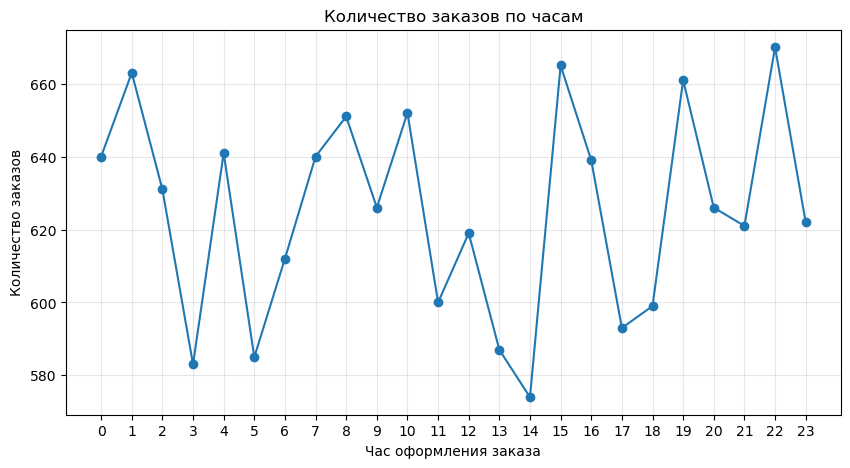


Количество заказов по часам:
order_hour
0     640
1     663
2     631
3     583
4     641
5     585
6     612
7     640
8     651
9     626
10    652
11    600
12    619
13    587
14    574
15    665
16    639
17    593
18    599
19    661
20    626
21    621
22    670
23    622
Name: order_id, dtype: int64

Час максимальной активности:
22
Количество заказов в этот час:
670


In [2]:
orders_by_hour = df_orders.groupby("order_hour")["order_id"].nunique()

plt.figure(figsize=(10, 5))
plt.plot(
    orders_by_hour.index,
    orders_by_hour.values,
    marker="o"
)

plt.title("Количество заказов по часам")
plt.xlabel("Час оформления заказа")
plt.ylabel("Количество заказов")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

print("\nКоличество заказов по часам:")
print(orders_by_hour)

print("\nЧас максимальной активности:")
print(orders_by_hour.idxmax())

print("Количество заказов в этот час:")
print(orders_by_hour.max())

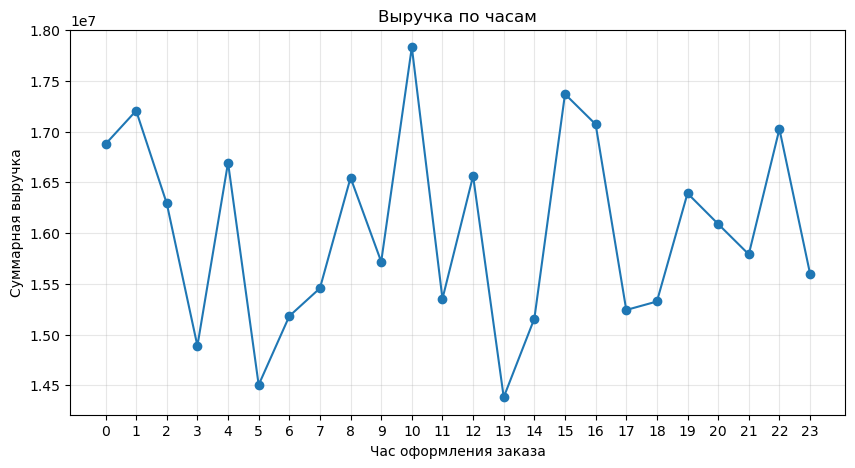


Выручка по часам:
order_hour
0     16876026.87
1     17205496.89
2     16291115.65
3     14888202.80
4     16693284.77
5     14503429.28
6     15181026.42
7     15456021.59
8     16545228.98
9     15717261.65
10    17830751.64
11    15352209.73
12    16562354.07
13    14382096.65
14    15157252.90
15    17369110.08
16    17071288.65
17    15241843.11
18    15325344.42
19    16391271.83
20    16088863.91
21    15789879.67
22    17024676.62
23    15599613.61
Name: revenue, dtype: float64

Час максимальной выручки:
10
Максимальная выручка:
17830751.64


In [3]:
revenue_by_hour = df_orders.groupby("order_hour")["revenue"].sum()

plt.figure(figsize=(10, 5))
plt.plot(
    revenue_by_hour.index,
    revenue_by_hour.values,
    marker="o"
)

plt.title("Выручка по часам")
plt.xlabel("Час оформления заказа")
plt.ylabel("Суммарная выручка")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

print("\nВыручка по часам:")
print(revenue_by_hour)

print("\nЧас максимальной выручки:")
print(revenue_by_hour.idxmax())

print("Максимальная выручка:")
print(revenue_by_hour.max())


In [4]:
max_orders_hour = orders_by_hour.idxmax()
max_revenue_hour = revenue_by_hour.idxmax()

print("\nЗадание 3. Сравнение максимальных значений:")

print(
    f"Максимальное количество заказов: "
    f"{max_orders_hour}:00 — {orders_by_hour.max()} заказов"
)

print(
    f"Максимальная выручка: "
    f"{max_revenue_hour}:00 — {revenue_by_hour.max():.2f}"
)


Задание 3. Сравнение максимальных значений:
Максимальное количество заказов: 22:00 — 670 заказов
Максимальная выручка: 10:00 — 17830751.64


In [ ]:
Количество заказов и выручка отражают разные показатели. 
В один час может быть много заказов с небольшим количеством недорогих товаров, 
а в другой — меньше заказов, но с более дорогими товарами или большим количеством позиций. 
Поэтому час максимального количества заказов может отличаться от часа максимальной выручки.

In [ ]:
В ходе практической работы были построены линейные графики количества заказов и суммарной выручки по часам. 
Установлено, что максимальное количество заказов наблюдается в 22:00 и составляет 670 заказов.
Максимальная выручка зафиксирована в 10:00 и составляет 17 830 751,64.
Часы максимального количества заказов и максимальной выручки не совпадают.
Это связано с тем, что суммарная выручка зависит не только от количества заказов,
но и от стоимости товаров и их количества в каждом заказе. 
В результате в час с меньшим количеством заказов может формироваться более высокая выручка.
Таким образом, анализ почасовой активности позволяет
выявить периоды наибольшего количества заказов и максимальных финансовых поступлений. 
Эти сведения могут использоваться для планирования работы интернет-магазина и анализа покупательского поведения.